# FBI through meida's client — one city's crime and its police force

`FbiClient` (`clients/fbi.py`) is meida's wrapper around the FBI Crime Data
Explorer and the layer the MCP tools sit on. This notebook is
[`api.ipynb`](api.ipynb)'s counterpart: that one is about the endpoints and the
ways they mislead, this one is about getting series out of them.

The FBI is a **live** source, like FRED, BLS and BIS and unlike WONDER and
NVSR. Nothing here is stored — there is no `time_series_source` row to read,
the catalog entry's `retrieval` block names a tool and its arguments rather
than a table, and every number below arrives over the wire while the cell runs.
What Postgres holds for the FBI is metadata: `series_catalog` rows saying what
can be fetched, built in [`catalog.ipynb`](catalog.ipynb).

The arc is one city. Washington's Metropolitan Police Department reports crime
and its own staffing to the same programme under the same identifier, so a
homicide series and a headcount series come out of one API — which is the
pairing section 5 draws. Three calls in all.

In [1]:
%reload_ext autoreload
%autoreload 2

import sys
from pathlib import Path

# Anchor on this notebook's own directory rather than on the working directory:
# VS Code can root a notebook at the workspace folder instead of at the file,
# and then a relative "../" resolves somewhere else entirely and the imports
# below fail with ModuleNotFoundError.
_here = Path.cwd()
_FBI = _here if (_here / "utils" / "mcp.py").exists() else _here / "notebooks" / "fbi"
for _path in (str(_FBI), str(_FBI.parents[1])):      # notebooks/fbi, then the meida root
    if _path not in sys.path:
        sys.path.insert(0, _path)

from datetime import datetime

import numpy
from matplotlib import pyplot
from matplotlib.figure import Figure
from numpy.typing import NDArray

from lib import config
from clients import FbiClient
from clients.models.fbi import FbiSeries

pyplot.style.use(config.glyfish_style)

ORI = "DCMPD0000"                  # Washington Metropolitan Police Department

Four helpers, kept here rather than in `utils/`, which is the catalog
builder's: periods into dates, a trailing sum, a count of how much of a window
was actually filed, and the stamp that names what a figure was drawn from.

`monthly` sorts. The CDE keys its periods `MM-YYYY`, which does not sort
chronologically as text — `sorted()` over those keys gives every January
first — so the observations arrive in month-major order and anything
sequential has to reorder them before touching them.

In [2]:
def monthly(series: FbiSeries) -> tuple[NDArray[numpy.object_], NDArray[numpy.float64]]:
    """A CDE monthly series as (dates, values), in date order.

    'MM-YYYY' sorts as text into all the Januaries, then all the Februaries,
    which is the order the observations come in; sorting on the parsed date is
    what makes a window mean twelve consecutive months.
    """
    points = []
    for observation in series.observations:
        month, year = observation.period.split("-")
        points.append((datetime(int(year), int(month), 1),
                       numpy.nan if observation.value is None else float(observation.value)))
    points.sort()
    return (numpy.array([date for date, _ in points]),
            numpy.array([value for _, value in points]))


def trailing_sum(values: NDArray[numpy.float64], window: int = 12) -> NDArray[numpy.float64]:
    """Twelve-month trailing sum, NaN until the window is full.

    A window holding a missing month stays NaN rather than summing eleven
    months as though they were twelve.
    """
    out = numpy.full(values.shape, numpy.nan)
    for end in range(window - 1, len(values)):
        span = values[end - window + 1:end + 1]
        if not numpy.isnan(span).any():
            out[end] = span.sum()
    return out


def filings(values: NDArray[numpy.float64], window: int = 12) -> NDArray[numpy.int_]:
    """How many months of each trailing window carry a filing, i.e. a non-zero."""
    out = numpy.zeros(values.shape, dtype=int)
    for end in range(window - 1, len(values)):
        span = numpy.nan_to_num(values[end - window + 1:end + 1])
        out[end] = int(numpy.count_nonzero(span))
    return out


def stamp_source(*names: str, figure: Figure | None = None) -> None:
    """Name the requests a figure was drawn from, along its bottom edge."""
    figure = figure or pyplot.gcf()
    figure.subplots_adjust(bottom=max(0.12, 0.06 + 0.035 * len(names)))
    figure.text(0.995, 0.005, "\n".join(names), ha="right", va="bottom",
                fontsize=7, family="monospace", alpha=0.65)

## 1. Discovery — from a city to an ORI

Every agency-scoped call is keyed by an **ORI**, the FBI's Originating Agency
Identifier, and `get_agencies` is the only route that enumerates them. It takes
a state and returns the whole registry for it, flattened out of the API's
per-county map; nationally that is 51 calls for 19,636 agencies, and here it is
one call for three.

Two fields do the choosing. `agency_type_name` says what kind of force it is —
the city department is the one whose beat is a place you can name, against a
transit police and a fire service — and `nibrs_start_date` says when *this*
agency began reporting under NIBRS. That date is per agency: Metro Transit
converted twenty-one years before the Metropolitan Police Department. It is not
a footnote to be read once and forgotten, either. Section 3 needs it to tell a
month with no crime in it from a month nobody filed.

In [3]:
async with FbiClient() as fbi:
    agencies = await fbi.get_agencies("DC")

for agency in sorted(agencies, key=lambda a: a.agency_type_name or ""):
    chosen = "->" if agency.ori == ORI else "  "
    print(f"{chosen} {agency.ori}  {(agency.agency_name or '')[:44]:44} "
          f"{agency.agency_type_name or '':6}  nibrs from {agency.nibrs_start_date or 'never'}")

department = next(agency for agency in agencies if agency.ori == ORI)
nibrs_start = datetime.strptime(department.nibrs_start_date, "%Y-%m-%d")

-> DCMPD0000  Washington Police Department                 City    nibrs from 2021-08-01
   DC0011300  District of Columbia Fire and Emergency Medi Other   nibrs from never
   DCMTP0000  Metro Transit Police                         Other   nibrs from 2000-01-01


## 2. One request, four series

`get_offenses` is parameterised by scope, offence and date range, and by
nothing else. Offences *and* clearances, each as a count *and* as a rate, come
back together, with the population denominator and the coverage percentage
alongside them. So `measure` and `unit` — which the catalog entries carry and
the MCP tool accepts — are selections made over a payload that is already in
hand, not arguments that reach the FBI. Anything caching this client should key
on the request; keyed on the caller's measure and unit, one payload's worth of
data costs four fetches.

The comparison geographies are the other half of the same point. An agency
request returns the agency, its state and the nation, widest first, and the
client drops the wider ones unless `include_comparisons` says otherwise. That
filter applies to the offence and clearance series; the population and coverage
rows keep the labels they came with, which is why two of the seven below are
titled "District of Columbia" — the jurisdiction — rather than the department.

In [4]:
async with FbiClient() as fbi:
    homicide = await fbi.get_offenses("homicide", ori=ORI, start="01-1985", end="12-2024")

print(f"{homicide.offense} / {homicide.scope} — vintage {homicide.max_data_date}, "
      f"refreshed {homicide.last_refresh_date}\n")
for series in homicide.series:
    first, final = series.span or ("none", "none")
    print(f"  {series.label:42} {series.measure:11} {str(series.unit):17} "
          f"{len(series.observations):4} points  {first}..{final}")

offences = next(s for s in homicide.series if s.measure == "offenses" and s.unit == "count")
clearances = next(s for s in homicide.series if s.measure == "clearances" and s.unit == "count")
coverage = next(s for s in homicide.series if s.unit == "percent")

homicide / DCMPD0000 — vintage 09/2026, refreshed 09/15/2026

  Washington Police Department Offenses      offenses    count              480 points  01-1985..12-2024
  Washington Police Department Clearances    clearances  count              480 points  01-1985..12-2024
  Washington Police Department Offenses      offenses    rate per 100,000   480 points  01-1985..12-2024
  Washington Police Department Clearances    clearances  rate per 100,000   480 points  01-1985..12-2024
  District of Columbia                       value       people             480 points  01-1985..12-2024
  Washington Police Department               value       people             480 points  01-1985..12-2024
  District of Columbia                       value       percent            480 points  01-1985..12-2024


## 3. The clearance rate

Clearances ÷ offences is the standard measure of enforcement intensity, and it
needs no second source: both legs arrived in the call above. The FBI's
definition of cleared is wider than "solved" — an offence clears on arrest *or*
by exceptional means, where the suspect is dead or beyond extradition or the
victim will not cooperate — so the ratio is what the department closed, not
what a court confirmed.

Before dividing, look at what a month is. Every one of those 480 periods holds
a number and none of them is null, so the series *reports* as complete; below
is what the months actually contain.

In [5]:
dates, offence_counts = monthly(offences)
_, clearance_counts = monthly(clearances)

print(f"nulls: {numpy.isnan(offence_counts).sum()} of {len(dates)} months        "
      f"zeros: {int((offence_counts == 0).sum())}\n")
print("        jan  feb  mar  apr  may  jun  jul  aug  sep  oct  nov  dec    year")
for measure, values in (("offences", offence_counts), ("clearances", clearance_counts)):
    print(f"  monthly homicide {measure}, as filed")
    filed = {(date.year, date.month): value for date, value in zip(dates, values)}
    for year in (1992, 1993, 1994, 1996, 1997, 2020, 2021):
        months = [filed[(year, month)] for month in range(1, 13)]
        print(f"  {year}  " + " ".join(f"{value:4.0f}" for value in months)
              + f"   {sum(months):5.0f}")

nulls: 0 of 480 months        zeros: 36

        jan  feb  mar  apr  may  jun  jul  aug  sep  oct  nov  dec    year
  monthly homicide offences, as filed
  1992    35   35   32   30   41   34   34   45   45   44   28   40     443
  1993     0    0  113    0    0  113    0    0  113    0    0  115     454
  1994    35   28   35   33   30   30   36   29   30   36   37   40     399
  1996     0    0    0    0    0  198    0    0    0    0    0  199     397
  1997     0    0    0    0    0    0    0    0    0    0    0  301     301
  2020    15   11   10   11   16   16   29   16   17   22   19   16     198
  2021     0    0    0    0    0    0    0   26   22   32   18   18     116
  monthly homicide clearances, as filed
  1992    20   28   16   20   21   12   24   28   18   15    5   25     232
  1993     0    0   59    0    0   59    0    0   59    0    0   60     237
  1994    19   19   19   19   19   19   19   19   19   19   19   22     231
  1996     0    0    0    0    0   48    0    

**The monthly grain is a filing schedule, not a measurement.** A zero is a
month in which the department filed nothing, and the number that follows says
where the missing months went.

* **1993 filed quarterly** — 113, 113, 113, 115 in March, June, September and
  December. The year totals 454 and the quarters are intact; only their spread
  across the months is fiction.
* **1996 filed twice and 1997 once**, the whole of 1997 landing in December.
  The same story, coarser.
* **1994 needs no zero to be wrong.** Its clearances are 19 in every month but
  the last — an annual figure spread flat — and nothing in the payload marks
  it.
* **2021 is the one that is actually missing.** Seven zeros to July, then
  ordinary months, 26 and 22 and 32, rather than one large catch-up. Nothing
  was pooled: SRS returns stopped on 1 January, this department's NIBRS
  returns began on `nibrs_start_date`, 1 August, and the months between went to
  neither system. Its 116 is not Washington's 2021.

Two consequences, pulling in different directions.

A **twelve-month total anchored on December** survives pooling, because a
filing that covers part of a year sits entirely within the year. That is why
1993's 454 and 1997's 301 below are right with 4 and 1 of their twelve months
filed, and it is a better reason for the trailing sum than smoothing is. The
ratio survives too, and for a different reason: both legs are pooled the same
way, so 2021's rate is the rate over the five months that exist even though its
counts are not the year.

A **window that splits a pooled filing** is nonsense in both directions, and
nothing in the window says which sort it is. So anything drawn as a monthly
series needs a stricter rule than this table's, which section 5 applies.

One caveat neither fixes: these are clearances *recorded* in the window, not
clearances *of* the offences in it. A department closing old cases can pass
100%, and does here. It is a rate of closing activity, not a solve rate.

In [6]:
annual_offences = trailing_sum(offence_counts)
annual_clearances = trailing_sum(clearance_counts)
clearance_rate = 100.0 * annual_clearances / annual_offences
months_filed = filings(offence_counts)

reported = {o.period: o.value for o in coverage.observations if o.value is not None}
december = {date.year: i for i, date in enumerate(dates) if date.month == 12}

print("Washington PD homicide, the twelve months to each December")
print("  year  offences  clearances    rate   filed  coverage")
for year in (1985, 1990, 1993, 1996, 1997, 2000, 2005, 2010,
             2015, 2019, 2020, 2021, 2022, 2023, 2024):
    i = december[year]
    print(f"  {year}  {annual_offences[i]:8.0f}  {annual_clearances[i]:10.0f}  "
          f"{clearance_rate[i]:6.1f}%  {months_filed[i]:2d}/12  "
          f"{reported.get(f'12-{year}', float('nan')):7.1f}%")

best = int(numpy.nanargmax(clearance_rate))
print(f"\nhighest twelve months: {clearance_rate[best]:.1f}% to {dates[best]:%m-%Y} — "
      f"{annual_clearances[best]:.0f} clearances against {annual_offences[best]:.0f} offences")

Washington PD homicide, the twelve months to each December
  year  offences  clearances    rate   filed  coverage
  1985       147          95    64.6%  12/12    100.0%
  1990       472         265    56.1%  12/12    100.0%
  1993       454         237    52.2%   4/12    100.0%
  1996       397          95    23.9%   2/12    100.0%
  1997       301          76    25.2%   1/12    100.0%
  2000       239          74    31.0%  12/12    100.0%
  2005       195         119    61.0%  12/12    100.0%
  2010       132         104    78.8%  12/12    100.0%
  2015       162         100    61.7%  12/12    100.0%
  2019       166         113    68.1%  12/12    100.0%
  2020       198         136    68.7%  12/12    100.0%
  2021       116          35    30.2%   5/12    100.0%
  2022       207          90    43.5%  12/12    100.0%
  2023       267         107    40.1%  12/12    100.0%
  2024       181          82    45.3%  12/12    100.0%

highest twelve months: 102.1% to 06-2012 — 98 clearances aga

## 4. Capacity — the same department's sworn officers

`get_employment` is the other half of the pairing, and it is agency-only:
`pe/national` and `pe/state/{ST}` answer 200 with the full response shape and
every value null, so the ORI found in section 1 is not a convenience here, it
is the only way in. The figures are annual from 1985, and the endpoint refuses
an earlier start rather than clamping it.

`FbiEmploymentResponse.officers` sums the male and female counts into sworn
officers per year, and it builds them from `actuals` rather than from the
`rates` block the payload also carries — that block divides by a "participated
population" that is sometimes zero, which is the third of `api.ipynb`'s traps.
Civilian staff arrive in the same payload and are left out of the total; a
sworn officer is the unit that compares across departments.

This series has none of section 3's trouble. It is filed once a year, it is a
headcount rather than an event count, and it does not care which reporting
system the crimes were filed under.

In [7]:
async with FbiClient() as fbi:
    employment = await fbi.get_employment(ORI)

officers = employment.officers
years = numpy.array(sorted(officers))
headcount = numpy.array([officers[year] for year in years])
peak, last = int(years[headcount.argmax()]), int(years[-1])
milestones = {int(years[0]): "the first year the programme reports",
              peak: "peak",
              2019: "the year before the pandemic",
              last: f"{100 * (officers[last] / headcount.max() - 1):+.0f}% on the peak"}

print(f"{employment.ori} — {len(years)} annual figures, {years[0]}–{years[-1]}, "
      f"no gaps\n")
for year, note in sorted(milestones.items()):
    print(f"  {year}  {officers[year]:>6,}   {note}")

print(f"\nmeasures in the payload: "
      f"{', '.join(sorted({s.measure for s in employment.series}))}")

DCMPD0000 — 40 annual figures, 1985–2024, no gaps

  1985   3,837   the first year the programme reports
  1990   4,740   peak
  2019   3,809   the year before the pandemic
  2024   3,276   -31% on the peak

measures in the payload: civilians, officers, value


## 5. Crime against capacity

One city, one API, two series that are usually two projects: the homicides the
department recorded and the officers it employed while recording them. Both
lines run 1985–2024, crime as the twelve-month trailing total so that section
3's filing schedule does not drive its shape.

Here the stricter rule. A month with no filing is missing, and so is the filing
that lands immediately after a run of missing months, because it may be
carrying them — 1993's quarters and 1997's single December plainly are. Any
twelve-month window touching either is dropped, which leaves the line broken
over 1993, 1996 to 1998, and 2021 into 2022. Drawn without that rule the line
spikes to 536 in November 1998, a window holding all of 1997's catch-up and
most of 1998's months: an artefact with the shape of a crime wave.

The shaded band is the hole the registry dates — 1 January 2021 to this
department's NIBRS start on 1 August. The officer line runs straight through
it, which is the honest asymmetry: the break is in how offences were filed, not
in how many people worked there.

**Read it as two series on one page, not as a relation.** Officers peak in 1990
and homicides in 1991, both fall through the decade after, both turn in the
2020s. Nothing in the picture separates staffing from the crack epidemic's arc,
from the city's population, or from the 2021 change in what an offence record
is.

36 months unfiled, 8 catch-ups that may carry them, leaving 392 of 480 windows drawable


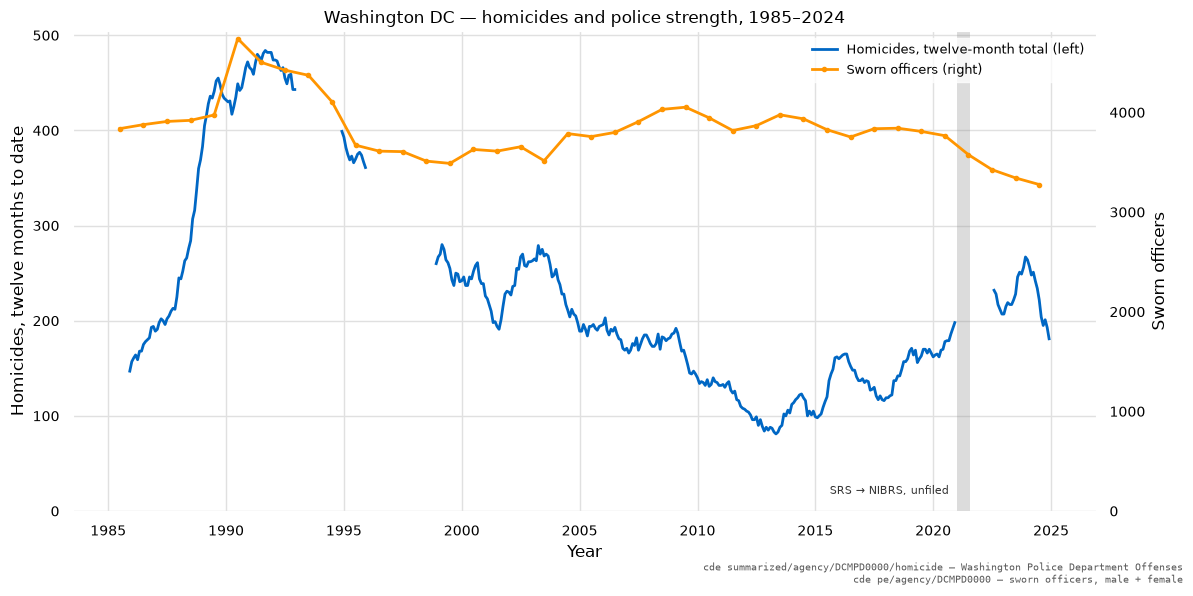

In [8]:
# A zero is a month nobody filed; the filing after a run of zeros may be a
# catch-up covering that run rather than a month of its own. Neither can be
# read as a month, and trailing_sum then drops every window that touches one.
unfiled = offence_counts == 0
carried = numpy.concatenate(([False], unfiled[:-1] & ~unfiled[1:]))
suspect = unfiled | carried
rolling_offences = trailing_sum(numpy.where(suspect, numpy.nan, offence_counts))

print(f"{int(unfiled.sum())} months unfiled, {int(carried.sum())} catch-ups that may "
      f"carry them, leaving {int(numpy.isfinite(rolling_offences).sum())} of "
      f"{len(dates)} windows drawable")

blue, orange = pyplot.rcParams["axes.prop_cycle"].by_key()["color"][:2]

figure, axis = pyplot.subplots(figsize=(12, 6))
axis.axvspan(datetime(2021, 1, 1), nibrs_start, color="0.55", alpha=0.3, lw=0)
axis.text(datetime(2021, 1, 1), 0.03, "SRS → NIBRS, unfiled  ",
          transform=axis.get_xaxis_transform(),
          ha="right", va="bottom", fontsize=8, alpha=0.8)

crime = axis.plot(dates, rolling_offences, color=blue, lw=2,
                  label="Homicides, twelve-month total (left)")
axis.set_ylabel("Homicides, twelve months to date")
axis.set_xlabel("Year")
axis.set_ylim(0, None)

capacity = axis.twinx()
capacity.grid(False)                    # the left axis already draws one
# An annual figure sits at mid-year rather than on the January boundary.
staff = capacity.plot([datetime(year, 7, 1) for year in years], headcount, color=orange,
                      lw=2, marker="o", markersize=3, label="Sworn officers (right)")
capacity.set_ylabel("Sworn officers")
capacity.set_ylim(0, None)

axis.set_title("Washington DC — homicides and police strength, 1985–2024", fontsize=12)
handles = crime + staff
axis.legend(handles, [str(handle.get_label()) for handle in handles], loc="upper right", fontsize=9)
figure.tight_layout()
stamp_source(f"cde summarized/agency/{ORI}/homicide — {offences.label}",
             f"cde pe/agency/{ORI} — sworn officers, male + female",
             figure=figure)

## What this supports, and what it does not

**Supports.** A city panel. Every department in the registry answers the same
two calls, so the pair above generalises to any ORI at eleven calls a city —
ten offence slugs and one employment pull — against an allowance of a thousand
an hour. The clearance rate comes free with the offence counts, which makes
enforcement intensity a property of the crime series rather than a second
dataset to find, and `nibrs_start_date` makes each department's break a date
rather than a guess.

**Does not.** Three limits, in the order they bite.

*The 2021 break is two breaks, and this city shows both.* The seven unfiled
months are the visible one. The other is that SRS applied the hierarchy rule —
one offence per incident — while NIBRS records every offence in an incident, so
the 2022 counts are not measured the way the 2019 counts were. Homicide is the
offence least disturbed by that, sitting at the top of the hierarchy, but any
statistic computed across the join — a trend, a change point, a regression with
a dummy — is reading a change in the counting rule as well as a change in
crime.

*Coverage will not warn you.* The last column of section 3 reads 100% in every
year printed, including 2021, because the jurisdiction's one department is on
the books throughout. Nationally that figure falls to 74% in 2021, which is
what makes it worth carrying beside a national series. It measures which
agencies are in the programme, not whether a given month was filed, and here
those two answers disagree for seven months. The number that caught it was
`nibrs_start_date`, from the registry, not the coverage series.

*Two series, not a model.* The figure is a pairing and the caveat under it is
this notebook's, not the API's. What the FBI supplies is the offence count and
the headcount; the population, the composition and every confounder between
them are somebody else's source.